In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

In [3]:
df = pd.read_csv("../Datasets/Mall_Customers.csv")

df.sample(5)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
145,146,Male,28,77,97
48,49,Female,29,40,42
168,169,Female,36,87,27
33,34,Male,18,33,92
152,153,Female,44,78,20


In [4]:
df.shape

(200, 5)

In [5]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Select annual income and spending score for clustering
# X = df.drop(columns=["CustomerID", "Gender", "Age"])
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
y = df["CustomerID"]

In [13]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

wcss

[269981.28,
 181363.595959596,
 106348.37306211119,
 73679.78903948836,
 44448.45544793371,
 37233.81451071001,
 30241.34361793659,
 25036.417604033988,
 21916.794789843727,
 20072.070939404002]

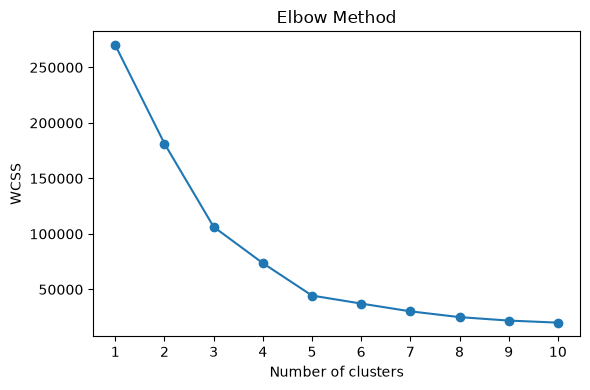

In [14]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()

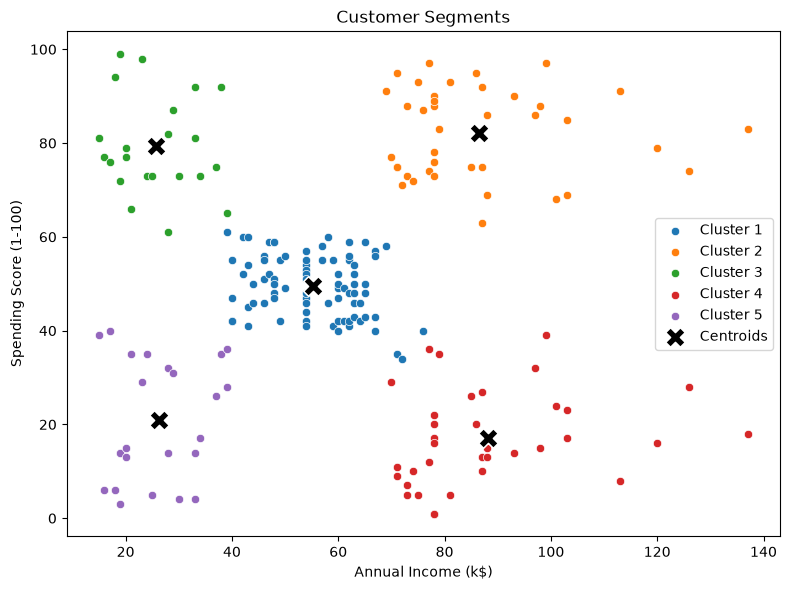

In [19]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X)

plt.figure(figsize=(8, 6))
for i in range(5):
    sns.scatterplot(x=X[y_pred == i]["Annual Income (k$)"], y=X[y_pred == i]["Spending Score (1-100)"], label=f'Cluster {i+1}')

sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], s=200, color='black', label='Centroids', marker='X')

plt.title('Customer Segments')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.tight_layout()
plt.show()